<a href="https://colab.research.google.com/github/miqi4/ML2026/blob/main/TG_244107020105_MOHAMMAD_IQBAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas matplotlib numpy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
import pandas as pd

df = pd.read_csv('/content/Titanic-Dataset.csv')
df.head(100)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,0,3,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
97,98,1,1,"Greenfield, Mr. William Bertram",male,23.0,0,1,PC 17759,63.3583,D10 D12,C
98,99,1,2,"Doling, Mrs. John T (Ada Julia Bone)",female,34.0,0,1,231919,23.0000,NaN,S


In [6]:
df.shape

(891, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


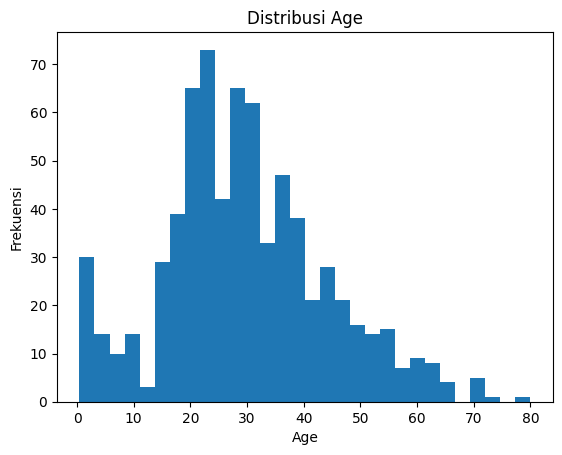

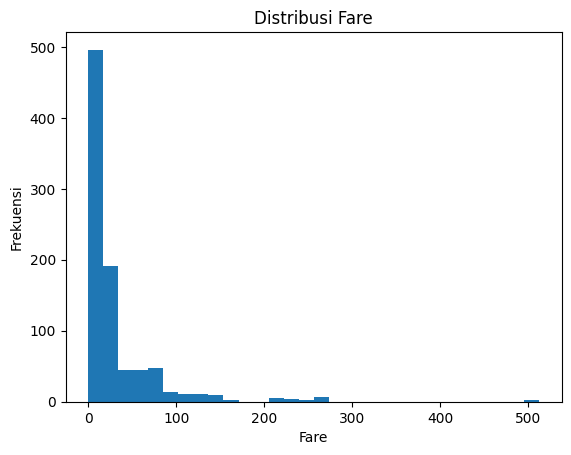

In [10]:
num_cols = ['Age','Fare']
for col in num_cols:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col); plt.ylabel('Frekuensi')
    plt.show()

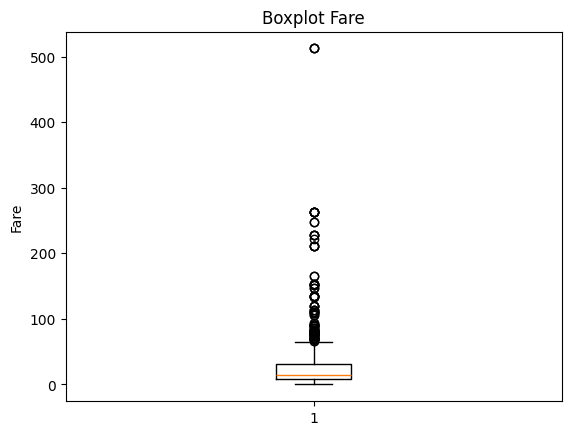

In [11]:
plt.figure()
plt.boxplot(df['Fare'].dropna(), vert=True)
plt.title('Boxplot Fare')
plt.ylabel('Fare')
plt.show()

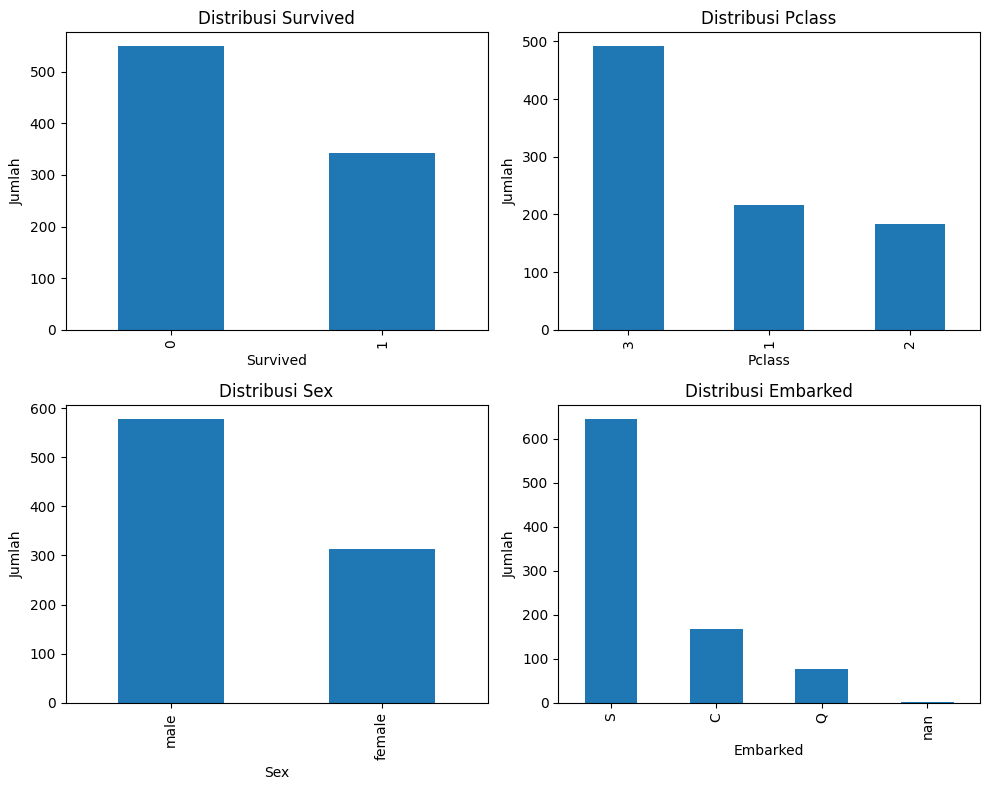

In [12]:
cat_cols = ['Survived','Pclass','Sex','Embarked']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    df[col].value_counts(dropna=False).plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

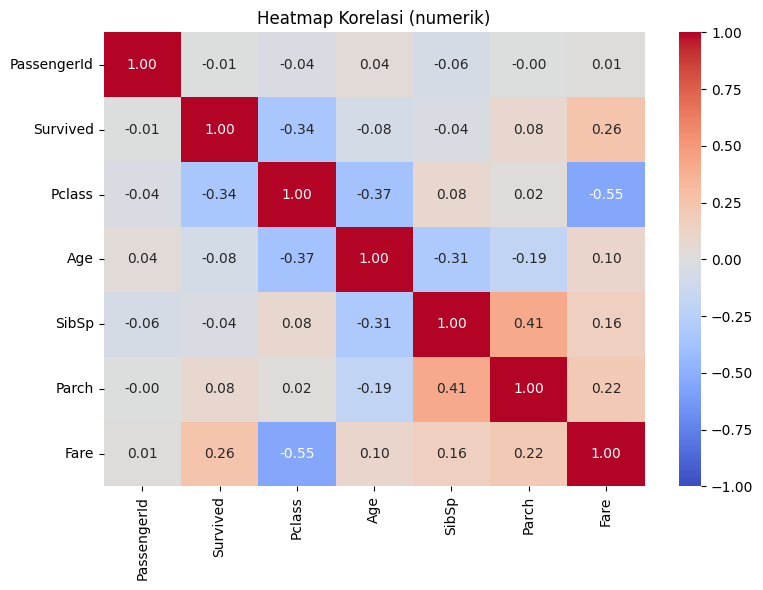

In [13]:
import seaborn as sns # Import seaborn for enhanced visualization

num_only = df.select_dtypes(include=[np.number])
corr = num_only.corr(numeric_only=True)

plt.figure(figsize=(8, 6)) # Increased figure size for better readability
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt=".2f") # Use seaborn.heatmap with annotation
plt.title('Heatmap Korelasi (numerik)')
plt.tight_layout()
plt.show()

In [14]:
corr['Survived'].sort_values(ascending=False)

,Survived
Survived,1.000000
Fare,0.257307
Parch,0.081629
PassengerId,-0.005007
SibSp,-0.035322
Age,-0.077221
Pclass,-0.338481


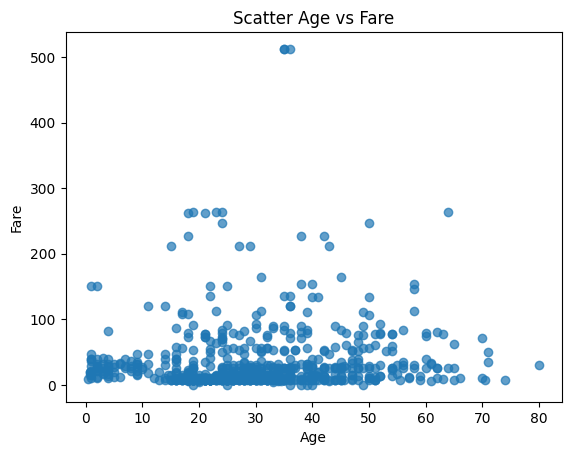

In [15]:
plt.figure()
surv_map = {0:'No', 1:'Yes'}
plt.scatter(df['Age'], df['Fare'], alpha=0.7)
plt.xlabel('Age'); plt.ylabel('Fare')
plt.title('Scatter Age vs Fare')
plt.show()

In [19]:
# Isi Age dengan nilai rata-rata
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Isi Cabin yang kosong
df['Cabin'] = df['Cabin'].fillna("DECK")

# Isi Embarked dengan nilai yang paling sering muncul
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Tampilkan 5 data teratas
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,DECK,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,DECK,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,DECK,S


In [26]:
path = 'data/Titanic-Dataset-fixed.csv'
df = pd.read_csv('/content/Titanic-Dataset.csv')
df.head()

In [24]:
df = df[['Survived', 'Pclass', 'Age', 'Sex', 'Cabin']]
df.head()

,Survived,Pclass,Age,Sex,Cabin
0,0,3,22.0,male,NaN
1,1,1,38.0,female,C85
2,1,3,26.0,female,NaN
3,1,1,35.0,female,C123
4,0,3,35.0,male,NaN


In [29]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder() # membuat objek dari LabelEncoder
df['Sex'] = le.fit_transform(df['Sex']) # proses encoding
df['Cabin'] = le.fit_transform(df['Cabin']) # proses encoding
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,147,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,81,C
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,147,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,55,S
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,147,S


In [31]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
df['Age'] = std.fit_transform(df[['Age']])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,-0.530377,1,0,A/5 21171,7.2500,147,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,0.571831,1,0,PC 17599,71.2833,81,C
2,3,1,3,"Heikkinen, Miss. Laina",0,-0.254825,0,0,STON/O2. 3101282,7.9250,147,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.365167,1,0,113803,53.1000,55,S
4,5,0,3,"Allen, Mr. William Henry",1,0.365167,0,0,373450,8.0500,147,S


In [35]:
!pip install -q opencv-python matplotlib
import cv2
import matplotlib.pyplot as plt
from google.colab import files

files.upload()

Saving Lenna.png to Lenna.png


{'Lenna.png': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02\x00\x00\x00\x02\x00\x08\x02\x00\x00\x00{\x1aC\xad\x00\x00\x00\x01sRGB\x00\xae\xce\x1c\xe9\x00\x07:\xa1IDATx\xda\xec\xe1]\x92m[\x92\x1d\xe6\x8d\xe1\xees\xae\xb5#\xe2\x9c{3\xab \x08\xe4\x8bZ \xa3\x8cFQ\xa4\xf1O%\xa3\x99:#\xa3\x00\xeaU\rP\xe3\xd4\x00Q\xa4\xc1\x00\x92H \xab\xb2\xf2\xde{"\xf6^kNw\x1fJ\xb5\x03\xf9}\xfc\xd7\xff\xaf\xff\'\x80\xc2\tm\xb7\x0b\xaf\xb4\xc7\xa1$\xa6w^\xae\xa3\xb4;\x7f\xf8\xe3\xbd\x92\xbd\x16\xc6B\r\x1e\'x\xf3sc$\xabj\x1cUts\xabm\xfb\x99\xe3\x9fBO\xf5\x9b\xc7\xa7\xe5\xeac\xfa\xaa:~\xb6~\xda\xfb\x87\xbd\xfe\xc1\x8e\xbf\x01o*\x9b\xc3\x8f`\xc3\xa7\xa5\xba\x13\x13MT.\xe3{\xe8\xb5\xba\x06\xefW\xf5\xa3~\xfdw\xcb\x8e>\xfe7\xeb\xcf\xff\xf8\xfc\\\xfa\xe5\xf3\xd78~|\xae\xfdu\x95\xf1\xea\xd8}\xd8\xfa\xc5>~\xff\x18{\xaf\xafq\x1c\xca\x8e\x08R!\x03\x92e\xe3\xf4\xb2\xcdl\xc9\xd0\xbb\x05\x9c\xb3\xe1\xb3\xab\xd5l\x13@VX$\nU\xf4(\x0c\xe7-\x1d\x89\xa5\xbdi6\xbah\xa3\xa2\x06&\xde\xdc?\x97\x85\xf9\xf0\x08"3\xaf\xfdx\x7fKT{\

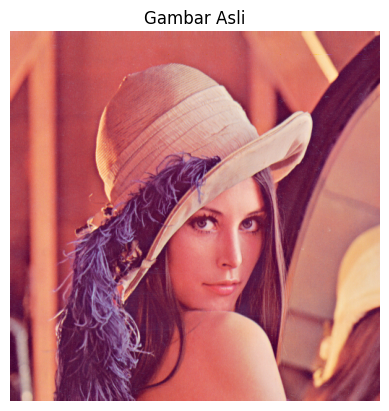

In [37]:
# Membaca gambar (BGR default di OpenCV)
img = cv2.imread("Lenna.png")

# Konversi BGR → RGB (agar warnanya tampil benar di matplotlib)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Tampilkan
plt.imshow(img_rgb)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

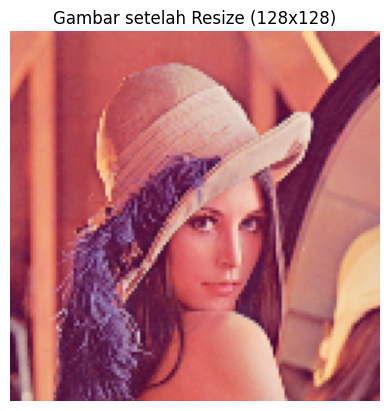

In [38]:
# Resize gambar
img_resized = cv2.resize(img_rgb, (128, 128))

plt.imshow(img_resized)
plt.title("Gambar setelah Resize (128x128)")
plt.axis("off")
plt.show()

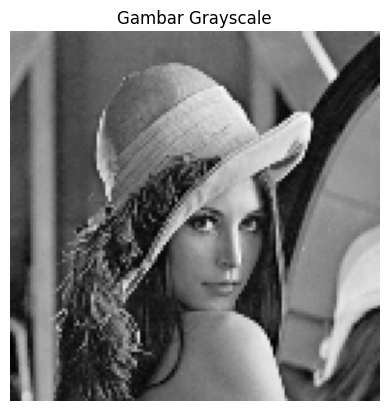

In [39]:
# Konversi ke grayscale
img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

plt.imshow(img_gray, cmap="gray")
plt.title("Gambar Grayscale")
plt.axis("off")
plt.show()

In [40]:
# 1. Import library
import pandas as pd
from google.colab import files
from sklearn.preprocessing import LabelEncoder, StandardScaler
# 2. Upload dataset
uploaded = files.upload()
# Membaca dataset
df = pd.read_csv('wbc.csv')
print("Ukuran dataset awal:", df.shape)
display(df.head())
# 3. Menghapus variabel yang tidak digunakan
df = df.drop(columns=['id', 'Unnamed: 32'])
print("Ukuran dataset setelah penghapusan:", df.shape)
# 4. Encoding diagnosis
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])
print("Encoding diagnosis:")
print(dict(zip(le.classes_, le.transform(le.classes_))))
# 5. Standardisasi variabel numerik
scaler = StandardScaler()
# Semua fitur kecuali diagnosis
feature_columns = df.columns.drop('diagnosis')
df[feature_columns] = scaler.fit_transform(df[feature_columns])
# 6. Melihat hasil akhir
print("\nData setelah preprocessing:")
display(df.head())

Saving wbc.csv to wbc.csv
Ukuran dataset awal: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Ukuran dataset setelah penghapusan: (569, 31)
Encoding diagnosis:
{'B': np.int64(0), 'M': np.int64(1)}

Data setelah preprocessing:


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,1,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100
